# IPO Listing Gain Prediction

**Notebook 3 of 5 - Feature Engineering**

## The Leakage Rule

Every feature has to be known **before** the IPO lists.

Subscription closes 3 working days before listing (T+3 rule from Dec 2023, before that up to 6 days). So for
market data only what was available **7 calendar days before** the listing date is used (`cutoff` date).
Using the listing day market would be data leakage (look-ahead).

## Features Built

| Group | Features | Idea |
|---|---|---|
| Subscription | `log_sub_qib`, `log_sub_hni`, `log_sub_rii`, `log_sub_total`, `qib_to_rii`, `fully_subscribed` | demand for the IPO |
| Issue | `log_issue_size`, `log_offer_price` | size and price of the issue |
| Relative subscription | `sub_total_vs_recent`, `sub_qib_vs_recent`, `sub_hni_vs_recent` | demand compared with the last 1 year |
| Market mood | `nifty_ret_1w`, `nifty_ret_1m`, `nifty_ret_3m`, `nifty_vs_200dma`, `vix` | is the market going up / calm? |
| Recent IPOs | `recent_ipo_count`, `recent_ipo_mean_gain` | how hot is the IPO market? |

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from useful_func import missing_info

# os -> check if market files exist, yfinance -> download NIFTY / VIX if they don't
import os
import yfinance as yf

sns.set_style("darkgrid")
fig_dir = "../reports/figures/"

In [2]:
# read dataset
ipos = pd.read_csv("../data/interim/ipos_verified.csv", parse_dates=["listing_date"])
# keep only rows with no exclude reason, sorted by listing date (old -> new)
ipos = ipos[ipos["exclude_reason"].fillna("") == ""].sort_values("listing_date", kind="mergesort").reset_index(drop=True)
# no peeking rule: market data only up to 7 days before listing
ipos["cutoff"] = ipos["listing_date"] - pd.Timedelta(days=7)   # last day whose information I can use
ipos.shape

(634, 31)

## Step 1: Subscription and Issue Features

**What we do:** Take `log1p` of the 4 subscription columns, log of issue size and offer price, plus
`qib_to_rii` (are institutions keener than retail?) and `fully_subscribed` (total >= 1x).

**Why we do it:** Subscription ranges from 0.5x to 1000x+ (and can be 0) - the log brings it to a usable scale,
as the histograms below show.

In [3]:
# start the feature table with the columns we already have
feat = ipos[["ipo_id", "ipo_name", "symbol", "listing_date", "sub_qib", "sub_hni", "sub_rii", "sub_total",
             "issue_size_cr", "offer_price", "target_gain_pct", "target_source"]].copy()
feat["year"] = feat["listing_date"].dt.year

# log1p = log(1 + x), squeezes 1x...300x into 0.7...5.7 so huge values don't dominate
# (+1 so that 0x doesn't give log(0))
for col in ["sub_qib", "sub_hni", "sub_rii", "sub_total"]:
    feat["log_" + col] = np.log1p(feat[col])
# were big institutions keener than normal people? (difference of logs = ratio)
feat["qib_to_rii"] = feat["log_sub_qib"] - feat["log_sub_rii"]
# 1 if at least fully subscribed, else 0
feat["fully_subscribed"] = (feat["sub_total"] >= 1).astype(int)
# size and price are never 0, so plain log is fine here
feat["log_issue_size"] = np.log(feat["issue_size_cr"])
feat["log_offer_price"] = np.log(feat["offer_price"])
feat.head()

,ipo_id,ipo_name,symbol,listing_date,sub_qib,sub_hni,sub_rii,sub_total,issue_size_cr,offer_price,...,target_source,year,log_sub_qib,log_sub_hni,log_sub_rii,log_sub_total,qib_to_rii,fully_subscribed,log_issue_size,log_offer_price
0,IPO0001,JSW Energy Limited,JSWENERGY,2010-01-04,2.88,0.15,0.40,1.68,2700.00,100.0,...,nse_open_yahoo,2010,1.355835,0.139762,0.336472,0.985817,1.019363,1,7.901007,4.605170
1,IPO0002,Godrej Properties Limited,GODREJPROP,2010-01-05,7.45,0.41,0.38,4.00,468.85,490.0,...,nse_open_yahoo,2010,2.134166,0.343590,0.322083,1.609438,1.812083,1,6.150283,6.194405
2,IPO0003,D B Corp Limited,DBCORP,2010-01-06,68.52,26.17,3.42,39.54,384.22,212.0,...,nse_open_yahoo,2010,4.241614,3.302113,1.486140,3.702289,2.755475,1,5.951215,5.356586
3,IPO0004,MBL Infrastructure Limited,MBLINFRA,2010-01-11,3.35,2.65,0.40,1.97,102.60,180.0,...,nse_open_yahoo,2010,1.470176,1.294727,0.336472,1.088562,1.133704,1,4.630838,5.192957
4,IPO0005,Birla Shloka Edutech Limited,NaN,2010-01-29,0.00,5.45,1.76,1.43,34.78,50.0,...,kaggle_unverified,2010,0.000000,1.864080,1.015231,0.887891,-1.015231,1,3.549043,3.912023


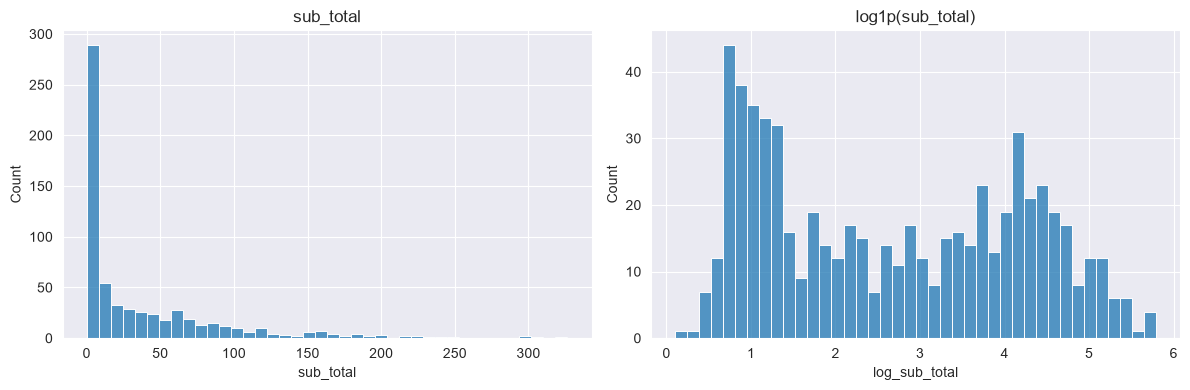

In [4]:
# before vs after log -> left is squashed to one side, right is spread out
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(feat["sub_total"], bins=40)
plt.title("sub_total")
plt.subplot(1, 2, 2)
sns.histplot(feat["log_sub_total"], bins=40)
plt.title("log1p(sub_total)")
plt.tight_layout()
plt.show()

## Step 2: Subscription Compared with the Last 1 Year

**What we do:** For each IPO, log subscription minus the median log subscription of IPOs that listed in the
previous 365 days (needs at least 5 of them).

**Why we do it:** Subscription numbers have gone up a lot over time (median by year below - 4.5x in 2019,
~30-40x in 2023-24). So 100x today is not the same as 100x in 2021. This puts each IPO against the norm of its
own time.

In [5]:
# median subscription per year -> it keeps going up over time (subscription inflation)
feat.groupby("year")["sub_total"].median()

year
2010     7.060
2011     1.700
2012     2.540
2013     6.640
2014    25.710
2015     2.040
2016    10.800
2017     8.240
2018     5.125
2019     4.545
2020    46.990
2021    29.040
2022     3.090
2023    31.650
2024    39.595
2025    29.365
2026     2.670
Name: sub_total, dtype: float64

In [6]:
# numpy arrays are faster to filter inside a loop than pandas
dates = ipos["listing_date"].to_numpy()
cutoffs = ipos["cutoff"].to_numpy()

# "was this line longer than usual for its time?"
# = own log subscription - median log subscription of IPOs in the 365 days before the cutoff
for col in ["sub_total", "sub_qib", "sub_hni"]:
    logged = np.log1p(ipos[col].to_numpy(dtype=float))
    vals = []
    for own, c in zip(logged, cutoffs):
        # past IPOs: listed before the cutoff, and not more than 365 days before it
        past = logged[(dates < c) & (dates >= c - np.timedelta64(365, "D")) & ~np.isnan(logged)]
        # need at least 5 past IPOs, otherwise the median is not reliable -> NaN
        vals.append(own - np.median(past) if len(past) >= 5 else np.nan)
    feat[col + "_vs_recent"] = vals

feat[["listing_date", "ipo_name", "sub_total", "sub_total_vs_recent"]].tail()

,listing_date,ipo_name,sub_total,sub_total_vs_recent
629,2026-04-02,Amir Chand Jagdish,3.23,-1.730829
630,2026-04-02,Powerica Ltd,1.45,-2.276942
631,2026-04-02,Sai Parenteral's L,1.05,-2.455191
632,2026-04-17,Om Power Transmiss,3.33,-1.641216
633,2026-05-08,Onemi Technology S,9.50,-0.724092


## Step 3: Market Mood - NIFTY 50 and India VIX

**What we do:** Download daily NIFTY 50 (`^NSEI`) and India VIX (`^INDIAVIX`) from Yahoo once, save to csv, and
compute:

| Feature | Formula |
|---|---|
| `nifty_ret_1w` / `1m` / `3m` | % change over 5 / 21 / 63 trading days |
| `nifty_vs_200dma` | % above or below the 200 day moving average |
| `vix` | India VIX close (expected volatility) |

**Why we do it:** IPOs usually list better when the overall market is rising and calm.

In [7]:
# download NIFTY 50 and India VIX history once and save, later runs read the saved csv
for name, ticker in [("nifty50", "^NSEI"), ("india_vix", "^INDIAVIX")]:
    path = f"../data/raw/market/{name}.csv"
    if not os.path.exists(path):
        h = yf.download(ticker, start="2009-01-01", auto_adjust=False, progress=False)
        h = h.droplevel(1, axis=1).rename(columns=str.lower)[["open", "high", "low", "close", "volume"]]
        h.rename_axis("date").to_csv(path)

# date column becomes the index
nifty = pd.read_csv("../data/raw/market/nifty50.csv", index_col="date", parse_dates=True)
vix = pd.read_csv("../data/raw/market/india_vix.csv", index_col="date", parse_dates=True)
print(f"Shape of nifty -: {nifty.shape}")
print(f"Shape of vix -: {vix.shape}")

Shape of nifty -: (4384, 5)
Shape of vix -: (4383, 5)


In [8]:
nifty.tail()

,open,high,low,close,volume
date,,,,,
2026-11-09,25076.400391,25084.050781,24838.750000,25044.650391,406200
2026-11-11,25337.800781,25424.349609,25095.349609,25255.050781,458000
2026-11-12,25213.500000,25384.800781,25142.949219,25299.349609,349200
2026-11-13,25209.849609,25246.349609,25054.400391,25144.300781,239600
2026-11-16,25206.150391,25337.599609,25190.250000,25253.550781,0


In [9]:
close = nifty["close"]
# market mood numbers for every trading day
# pct_change(5) = % change over the last 5 trading days (1 week), 21 = 1 month, 63 = 3 months
# nifty_vs_200dma = how far NIFTY is above (+) or below (-) its 200 day average
mkt = pd.DataFrame({
    "nifty_ret_1w": close.pct_change(5) * 100,
    "nifty_ret_1m": close.pct_change(21) * 100,
    "nifty_ret_3m": close.pct_change(63) * 100,
    "nifty_vs_200dma": (close / close.rolling(200, min_periods=150).mean() - 1) * 100,
})
# add VIX (market fear), ffill = if a day is missing use the last known value
mkt = mkt.join(vix["close"].rename("vix"), how="left").ffill()
# date back as a normal column (needed for merge_asof below)
mkt = mkt.rename_axis("date").reset_index()
mkt.dropna().head()

,date,nifty_ret_1w,nifty_ret_1m,nifty_ret_3m,nifty_vs_200dma,vix
149,2009-08-14,2.201319,8.239588,6.057720,26.488939,44.240002
150,2009-08-17,-1.121089,0.295997,2.753907,21.012508,46.490002
151,2009-08-18,-0.278444,-0.962854,5.889477,22.785039,45.040001
152,2009-08-19,-1.422320,-1.678190,3.671112,20.834785,40.209999
153,2009-08-20,-3.290984,1.240089,5.094935,22.288468,36.830002


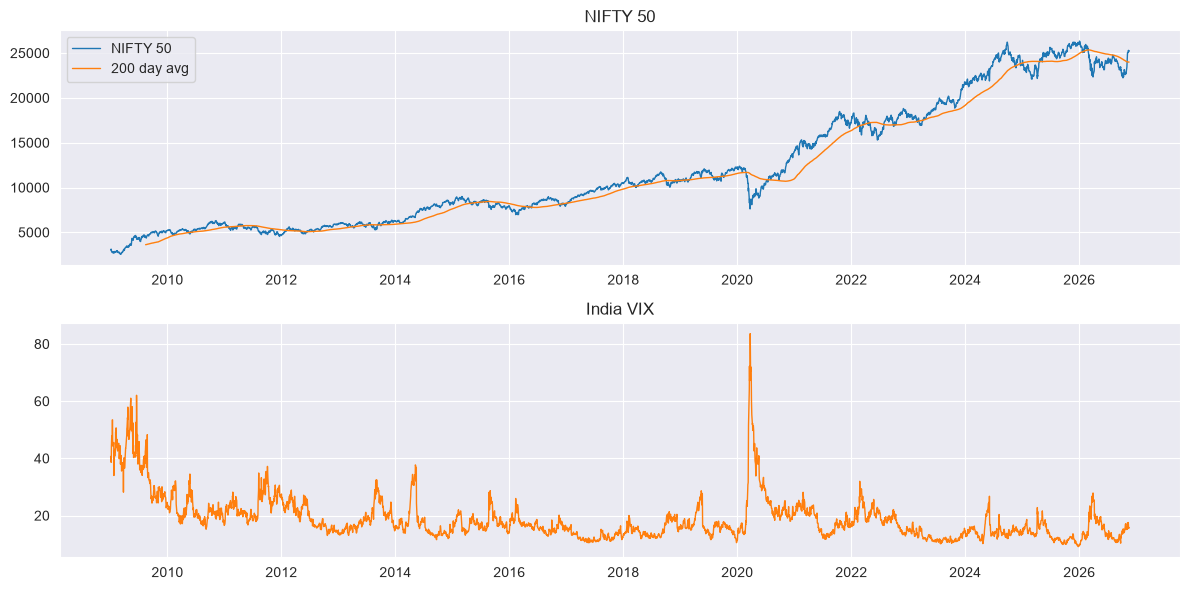

In [10]:
# top -> NIFTY with its 200 day average, bottom -> VIX
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(close.index, close, lw=1, label="NIFTY 50")
plt.plot(close.index, close.rolling(200, min_periods=150).mean(), lw=1, label="200 day avg")
plt.title("NIFTY 50")
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(vix.index, vix["close"], lw=1, color="tab:orange")
plt.title("India VIX")
plt.tight_layout()
plt.show()

**Matching to each IPO:** take the last trading day on or before the IPO's cutoff date
(`merge_asof` with `direction="backward"`). The check below must print **0** - no market date after the cutoff.

In [11]:
# for each IPO take the market row of the last trading day on or before its cutoff
# direction="backward" -> never looks forward in time
mood = pd.merge_asof(ipos[["cutoff"]], mkt, left_on="cutoff", right_on="date", direction="backward")
for col in ["nifty_ret_1w", "nifty_ret_1m", "nifty_ret_3m", "nifty_vs_200dma", "vix"]:
    feat[col] = mood[col].values

# check: market date used should never be after the cutoff
(mood["date"] > mood["cutoff"]).sum()

np.int64(0)

## Step 4: How Did Recent IPOs Do?

**What we do:** For each IPO, count the IPOs that listed in the 90 days before its cutoff and take their
average listing gain.

**Why we do it:** If recent IPOs listed well, investors get excited about the next one (and vice versa).

In [12]:
# how did the IPOs of the last 90 days (before the cutoff) do? -> hot or cold IPO market
gains = ipos["target_gain_pct"].to_numpy(dtype=float)
count, mean_gain = [], []
for c in cutoffs:
    # True for IPOs that listed in the 90 days before this cutoff
    w = (dates < c) & (dates >= c - np.timedelta64(90, "D")) & ~np.isnan(gains)
    count.append(int(w.sum()))
    # no IPO in that window -> NaN (filled later inside the model pipeline)
    mean_gain.append(gains[w].mean() if w.sum() else np.nan)

feat["recent_ipo_count"] = count
feat["recent_ipo_mean_gain"] = mean_gain
feat[["listing_date", "ipo_name", "recent_ipo_count", "recent_ipo_mean_gain"]].tail()

,listing_date,ipo_name,recent_ipo_count,recent_ipo_mean_gain
629,2026-04-02,Amir Chand Jagdish,15,2.069861
630,2026-04-02,Powerica Ltd,15,2.069861
631,2026-04-02,Sai Parenteral's L,15,2.069861
632,2026-04-17,Om Power Transmiss,18,0.435926
633,2026-05-08,Onemi Technology S,16,-3.775930


In [13]:
feat.shape

(634, 31)

In [14]:
# NaN here are expected (no past IPOs in the window), not data errors
missing_info(feat)

,column_name,num_missing,missing%
0,symbol,90,14.20
1,recent_ipo_mean_gain,12,1.89
2,sub_total_vs_recent,10,1.58
3,sub_qib_vs_recent,10,1.58
4,sub_hni_vs_recent,10,1.58


### Missing Values in the Feature Table

**Observations:**
- `symbol` is missing for the 90 IPOs that aren't on NSE's list anymore - not a model feature, so fine
- the other NaNs (10-12 rows) are at the start of the data (Jan 2010, no history yet) or after quiet stretches
  with no IPOs in the previous 90 days / year (2012-14, early 2019, mid 2020)

**Decision:** fill them with the median **inside the model pipeline** (`SimpleImputer`), so the median is
learnt from training data only.

In [15]:
# final feature table -> input of the modeling notebook
feat.to_csv("../data/processed/ipo_features.csv", index=False)

## Step 5: Quick Look at the New Features

**What we do:** Spearman correlation of every feature with the listing gain, and median gain by market trend
and by recent IPO results.

**Why we do it:** To check the new market features carry some signal before giving them to the model.

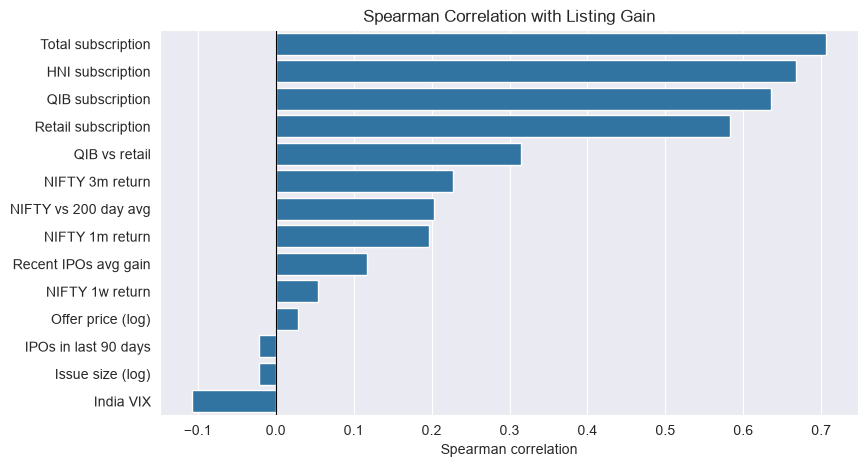

,feature,spearman
0,Total subscription,0.706418
1,HNI subscription,0.667463
2,QIB subscription,0.635202
3,Retail subscription,0.582856
4,QIB vs retail,0.314197
5,NIFTY 3m return,0.227080
6,NIFTY vs 200 day avg,0.203184
7,NIFTY 1m return,0.196987
8,Recent IPOs avg gain,0.116608
9,NIFTY 1w return,0.054737


In [16]:
# short readable names for the plot
names = {"log_sub_total": "Total subscription", "log_sub_hni": "HNI subscription", "log_sub_qib": "QIB subscription",
         "log_sub_rii": "Retail subscription", "qib_to_rii": "QIB vs retail", "nifty_ret_3m": "NIFTY 3m return",
         "nifty_vs_200dma": "NIFTY vs 200 day avg", "nifty_ret_1m": "NIFTY 1m return",
         "recent_ipo_mean_gain": "Recent IPOs avg gain", "nifty_ret_1w": "NIFTY 1w return",
         "log_offer_price": "Offer price (log)", "recent_ipo_count": "IPOs in last 90 days",
         "log_issue_size": "Issue size (log)", "vix": "India VIX"}
# spearman correlation of every feature with the listing gain
corr = feat[list(names) + ["target_gain_pct"]].corr(method="spearman")["target_gain_pct"].drop("target_gain_pct")
corr_df = corr.rename(index=names).sort_values(ascending=False).reset_index()
corr_df.columns = ["feature", "spearman"]

# horizontal bars, biggest at the top
plt.figure(figsize=(9, 5))
sns.barplot(data=corr_df, x="spearman", y="feature", color="tab:blue")
plt.axvline(0, color="black", lw=0.8)
plt.title("Spearman Correlation with Listing Gain")
plt.xlabel("Spearman correlation")
plt.ylabel("")
plt.savefig(fig_dir + "05_feature_correlation.png", dpi=120, bbox_inches="tight")
plt.show()
corr_df

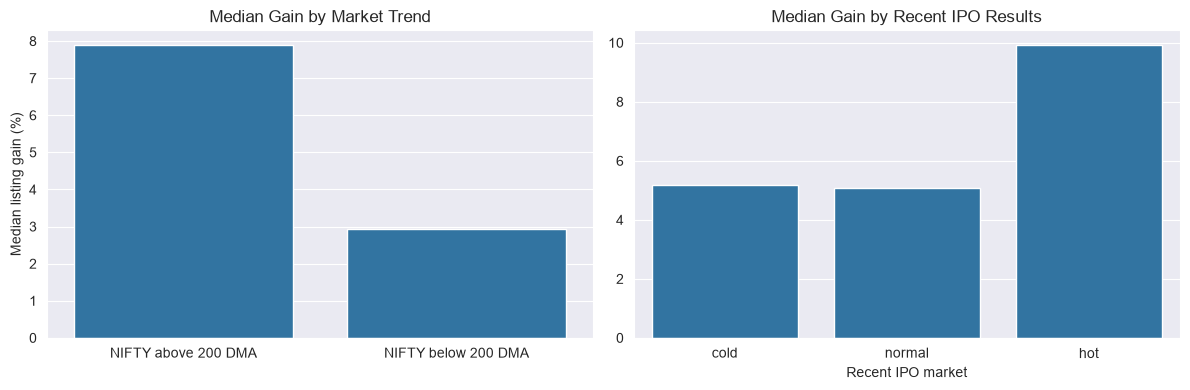

In [17]:
# label each IPO: market above / below its 200 day average
feat["market"] = np.where(feat["nifty_vs_200dma"] >= 0, "NIFTY above 200 DMA", "NIFTY below 200 DMA")
# split recent IPO gain into 3 equal groups -> cold / normal / hot
feat["heat"] = pd.qcut(feat["recent_ipo_mean_gain"], 3, labels=["cold", "normal", "hot"])

# median listing gain in each group
market_gain = feat.groupby("market")["target_gain_pct"].median().reset_index()
heat_gain = feat.groupby("heat", observed=True)["target_gain_pct"].median().reset_index()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.barplot(data=market_gain, x="market", y="target_gain_pct")
plt.title("Median Gain by Market Trend")
plt.xlabel("")
plt.ylabel("Median listing gain (%)")
plt.subplot(1, 2, 2)
sns.barplot(data=heat_gain, x="heat", y="target_gain_pct")
plt.title("Median Gain by Recent IPO Results")
plt.xlabel("Recent IPO market")
plt.ylabel("")
plt.tight_layout()
plt.savefig(fig_dir + "06_market_mood.png", dpi=120, bbox_inches="tight")
plt.show()

In [18]:
# same subscription groups as EDA
feat["sub_bucket"] = pd.cut(feat["sub_total"], [0, 1, 3, 10, 30, 100, 1e5],
                            labels=["<1x", "1-3x", "3-10x", "10-30x", "30-100x", "100x+"])
# inside the same subscription group, does market mood still change the gain?
feat.pivot_table(index="sub_bucket", columns="market", values="target_gain_pct", aggfunc="median", observed=True)

market,NIFTY above 200 DMA,NIFTY below 200 DMA
sub_bucket,,
<1x,0.000000,-1.895000
1-3x,-1.428571,1.279568
3-10x,4.086845,0.000000
10-30x,9.589041,17.831669
30-100x,21.666667,31.428571
100x+,57.332136,27.586207


**Observations:**
- subscription features have the strongest correlation (**~0.6 - 0.7**), market features are much weaker
  (**~0.2** for NIFTY returns / trend)
- NIFTY above its 200 day average: median gain **7.9%** vs **2.9%** below it
- hot recent IPO market: median gain **9.9%** vs **~5%** for cold / normal
- but inside the same subscription bucket it's mixed - 10-100x IPOs actually did better below the 200 DMA,
  100x+ IPOs much better above it

**Decision:** market mood is a weaker, secondary signal - keep it and let the model decide how much to use it.

## Summary

| | |
|---|---|
| IPOs | 634 |
| Columns | 31 (ids, raw values, target, 18 features) |
| Saved | `data/processed/ipo_features.csv` |

**Next notebook:** `04_modeling.ipynb`